In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.ticker as mticker
from matplotlib import colors
from matplotlib.colors import BoundaryNorm

import cartopy
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.crs as ccrs
from scipy import signal
from scipy.signal import periodogram
import eofs
import iris
import iris.quickplot as qplt 
import iris.plot as iplt
iris.FUTURE.netcdf_promote=True
import iris.coord_categorisation

/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/matplotlib/ticker.py:1693: UserWarning: Steps argument should be a sequence of numbers
increasing from 1 to 10, inclusive. Behavior with
values outside this range is undefined, and will
raise a ValueError in future versions of mpl.
  warnings.warn('Steps argument should be a sequence of numbers\n'


### Open Seawater age anomalies

In [2]:
## Seawater age diff
### Upload PI
path = '/nfs/hera1/ee22kvcs/PMIP4/'

models = [ 'ACCESS-ESM1-5', 'KCM', 'NorESM1-F', 'NorESM2-LM']
names_models_diff_age = ['agessc_diff_Oyr_ACCESS-ESM1-5_100ymean_regridded_360x385_intlevel.nc',
                   'agessc_diff_Oyr_KCM_r1i1p1f1_4901_5000_100yr_mean_intlevel.nc',
                   'agessc_diff_Oyr_NorESM1-F_r1i1p1f1_gr_1601-1700_100yr_mean_regridded_360x385_intlevel.nc',
                   'agessc_diff_Oyr_NorESM2-LM_r1i1p1f1_gr_2101-2200_100yr_mean_regridded_360x385_intlevel.nc']

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'agessc_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'agessc_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'agessc_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'agessc_diff')]

Diff_models_age = []
for i in range(np.size(models)):
    uploaded_cubes = iris.load_cube(path+names_models_diff_age[i], constraints[i])
    uploaded_cubes2 = iris.util.squeeze(uploaded_cubes)
    Diff_models_age.append(uploaded_cubes2)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

### MMM

In [4]:
### MMM
age_diff = [cube.copy() for cube in Diff_models_age]
MMM_diff_age = sum([Diff_models_age[i].data for i in range(np.size(Diff_models_age))])/4
MMM_diff_age_cube = Diff_models_age[0].copy(data = MMM_diff_age)

In [7]:
#### Spread
sig_diff_age = []
for n in range(np.size(Diff_models_age)):
    difference = Diff_models_age[n].data
    # Only count differences with magnitude >= 1
    # 1 corresponds to (+) differences, -1 to (-) differences, 0 to no significant differences
    signed_diff = np.where(difference >= 1, 1, np.where(difference <= -1, -1, 0))
    sig_diff_age.append(signed_diff)
# Sum
sum_sig_diff_age = np.sum(sig_diff_age, axis=0)
consensus_values_age = np.where(np.abs(sum_sig_diff_age) >= 3, sum_sig_diff_age, np.nan)
consensus_cube_age = MMM_diff_age_cube.copy(data=consensus_values_age)

non_consensus_age_mask = np.abs(sum_sig_diff_age) < 3
non_consensus_age_cube = MMM_diff_age_cube.copy(data=non_consensus_age_mask.astype(float))

/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/ipykernel/__main__.py:7: RuntimeWarning: invalid value encountered in greater_equal
/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/ipykernel/__main__.py:7: RuntimeWarning: invalid value encountered in less_equal


### Plot the Arabian Sea

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:988: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(self.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:1017: UserWarning: Collapsing a non-contiguous coordinate. Metadata may not be fully descriptive for 'longitude'.
  warnings.warn(msg.format(self.name()))


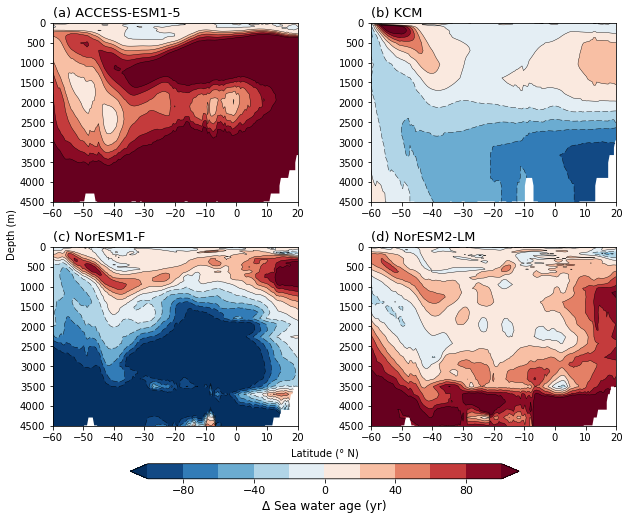

In [20]:
### Plot LIG-PI Arabian Sea zonal-mean meridional transect
titles = [ '(a) ACCESS-ESM1-5', '(b) KCM', '(c) NorESM1-F', '(d) NorESM2-LM']
depth_names = ['depth', 'plev', 'depth', 'depth']

# Arabian Sea longitude bounds (edit as needed)
lon_min, lon_max = 50, 75

fig = plt.figure(figsize=(9, 7))
axes = [fig.add_subplot(2, 2, i) for i in range(1, 5)]
im = None
for i, (ax, t, depth, cube) in enumerate(zip(axes, titles, depth_names, Diff_models_age)):
    lon_pts = cube.coord('longitude').points
    if lon_pts.max() > 180:
        lo, hi = lon_min % 360, lon_max % 360
    else:
        lo, hi = lon_min, lon_max

    # Arabian Sea longitudes
    region = cube.extract(iris.Constraint(longitude=lambda cell: lo <= cell.point <= hi))
    # zonal mean across longitudes
    section = region.collapsed('longitude', iris.analysis.MEAN)

    ax.set_yticks(np.arange(0, 5000 + 500, 500))
    ax.set_xticks(np.arange(-80, 80 + 10, 10))
    ax.tick_params(axis='x', labelsize=10)
    ax.tick_params(axis='y', labelsize=10)
    ax.set_ylim(0, 4500)
    ax.set_xlim(-60, 20)
    ax.set_title(t, fontsize=13, loc='left')
    levels = np.arange(-100, 100 + 20, 20)
    im = iplt.contourf(section, coords=['latitude', depth], axes=ax, levels=levels, cmap='RdBu_r', extend='both')
    im2 = iplt.contour(section, coords=['latitude', depth], axes=ax, colors='k', levels=levels, linewidths=0.4)
    
    if i == 1 or i == 2:
        ax.invert_yaxis()

plt.subplots_adjust(left=0.08, bottom=0.12, right=0.95, top=0.92, wspace=0.3, hspace=0.25)
cbar_ax = fig.add_axes([0.2, 0.015, 0.6, 0.03])
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Δ Sea water age (yr)', size=12)
cbar.ax.tick_params(labelsize=11)

fig.text(0.01, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=10)
fig.text(0.5, 0.06, 'Latitude (° N)', ha='center', fontsize=10)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/age_seawater_arabiansea_diff.png', bbox_inches='tight', dpi=300, format='png')
plt.show()

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:988: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(self.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:1017: UserWarning: Collapsing a non-contiguous coordinate. Metadata may not be fully descriptive for 'longitude'.
  warnings.warn(msg.format(self.name()))


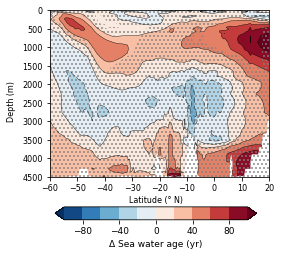

In [27]:
### Plot LIG-PI Arabian Sea MMM
# Arabian Sea longitudes
lon_min, lon_max = 50, 75
lon_pts = MMM_diff_age_cube.coord('longitude').points

if lon_pts.max() > 180:
    lo, hi = lon_min % 360, lon_max % 360
else:
    lo, hi = lon_min, lon_max

# Arabian Sea longitudes
region = MMM_diff_age_cube.extract(iris.Constraint(longitude=lambda cell: lo <= cell.point <= hi))
region_spread = non_consensus_age_cube.extract(iris.Constraint(longitude=lambda cell: lo <= cell.point <= hi))

# zonal mean
section = region.collapsed('longitude', iris.analysis.MEAN)
section_spread = region_spread.collapsed('longitude', iris.analysis.MEAN)

fig, ax = plt.subplots(figsize=(3.5, 3))
im = None

ax.set_yticks(np.arange(0, 5000 + 500, 500))
ax.set_xticks(np.arange(-80, 80 + 10, 10))
ax.tick_params(axis='x', labelsize=8)
ax.tick_params(axis='y', labelsize=8)
ax.set_ylim(0, 4500)
ax.set_xlim(-60, 20)
levels = np.arange(-100, 100 + 20, 20)
 
im = iplt.contourf(section, coords=['latitude', 'depth'], axes=ax, levels=levels, cmap='RdBu_r', extend='both')
im2 = iplt.contour(section, coords=['latitude', 'depth'], axes=ax, colors='k', levels=levels, linewidths=0.4)

mpl.rcParams['hatch.color'] = 'gray'
iplt.contourf(section_spread, coords=['latitude', 'depth'],axes=ax,levels=[0.5, 1.5],colors='none',hatches=['...'])

plt.subplots_adjust(left=0.08, bottom=0.15, right=0.95, top=0.92, wspace=0.3, hspace=0.2)
cbar_ax = fig.add_axes([0.1, -0.05, 0.8, 0.06]) # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Δ Sea water age (yr)', size=9)
cbar.ax.tick_params(labelsize=9)

fig.text(-0.09, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=8)
fig.text(0.5, 0.03, 'Latitude (° N)', ha='center', fontsize=8)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/age_seawater_o2_arabiansea_diff_mmm_v2.png', bbox_inches='tight', dpi=300, format='png')
plt.show()